Лабораторная работа №2

Вариант - paper-jsonl

№1

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)

№2 Проверка данных, работа со столбцом G

In [2]:
data=pd.read_json('records.jsonl',lines=True)
data.head()

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
0,W4386830175,Novel Terahertz-Based Radiation Treatment of A...,"Alzheimer’s Disease Facts and Figures, an annu...",NaN,Terahertz technology and applications,Engineering,2023,0,en,True,https://doi.org/10.47485/2694-5614.1020
1,W4407611995,استخدام مفاهيم التصميم العالمى فى مدارس التعلي...,الملخص: تتناول الدراسة سبل تحقيق الاستدامة الا...,Dina Hassan Helaly Ali Ahmed,Military Technology and Strategies,Engineering,2025,0,ar,True,https://doi.org/10.21608/auber.2025.287359.1083
2,W7154576169,A Behavioral Approach to Understanding Loss Re...,This paper takes a deep dive into historical l...,Uri Korn,Credit Risk and Financial Regulations,"Economics, Econometrics and Finance",2023,0,en,True,https://doi.org/10.66573/001c.87684
3,W4405618890,ВЫРАЗИТЕЛЬНЫЕ ВОЗМОЖНОСТИ СОВРЕМЕННОЙ КИТАЙСКО...,В статье анализируется комплекс выразительных ...,Ю. Ли,Musicology and Musical Analysis,Arts and Humanities,2024,0,ru,True,https://doi.org/10.26176/maetam.2024.16.3.004
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886


In [3]:
data.info()
data['field']=data['field'].fillna('Неизвестно')
copy_data=data.copy()
data_break=data.copy()
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2000 non-null   str  
 1   title        2000 non-null   str  
 2   abstract     2000 non-null   str  
 3   authors      1984 non-null   str  
 4   topic        1995 non-null   str  
 5   field        1995 non-null   str  
 6   year         2000 non-null   int64
 7   citations    2000 non-null   int64
 8   language     1899 non-null   str  
 9   open_access  2000 non-null   bool 
 10  url          2000 non-null   str  
dtypes: bool(1), int64(2), str(8)
memory usage: 158.3 KB
<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2000 non-null   str  
 1   title        2000 non-null   str  
 2   abstract     2000 non-null   str  
 3   authors      1984 non-null

№3 Выбираем жертв

In [4]:
victims=data.sample(frac=0.1, random_state=SEED)
indexes=victims.index.tolist()
victims

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
1860,W4413852931,Enzymatic pathways in sweet potato (Ipomoea ba...,Starch is a critical carbohydrate stored in th...,James Kamau | Esther Njiru,Cassava research and cyanide,Agricultural and Biological Sciences,2025,1,en,True,https://doi.org/10.33545/26174693.2025.v9.i8m....
353,W4398211476,Long‐term ecological responses to landscape‐sc...,Tree thinning and the application of prescribe...,John Paul Roccaforte | David W. Huffman | Kyle...,Fire effects on ecosystems,Environmental Science,2024,7,en,True,https://doi.org/10.1111/rec.14181
1333,W7203999391,PENGARUH BRAND EQUITY DAN ONLINE REVIEWS TERHA...,The growth of the internet is affecting market...,Rihan Hafizni | Evita Sandra,Consumer Behavior and Marketing Influence,"Business, Management and Accounting",2022,0,NaN,True,https://doi.org/10.34308/eqien.v9i2.428
905,W2977799777,Polski Instytut Naukowy na nowo odkrywany. Rec...,brak,Barbara Czarnecka,Polish Historical and Cultural Studies,Social Sciences,2020,0,pl,True,https://openalex.org/W2977799777
1289,W4282945339,Aplastic anemia induced by human parvovirus B1...,Introduction and importance: Parvovirus B19 (B...,Ayush Mohan Bhattarai | Bishal Dhakal | Pooja ...,Parvovirus B19 Infection Studies,Medicine,2022,8,en,True,https://doi.org/10.1016/j.amsu.2022.103998
...,...,...,...,...,...,...,...,...,...,...,...
462,W4377115566,Design and Viability Assessment of Grid-Integr...,"Recently, the demand for electric power supply...",Jelili Aremu Oyedokun | Emmanuel Taiwo Fasina ...,Energy and Environment Impacts,Environmental Science,2023,3,en,True,https://doi.org/10.24018/ejece.2023.7.3.507
1105,W4282547188,Influence of Freeze–Thaw Cycles on Physical an...,The problem of weak ground conditions is curre...,Nazerke Sagidullina | Shynggys Abdialim | Jong...,Geotechnical Engineering and Soil Stabilization,Engineering,2022,37,en,True,https://doi.org/10.3390/su14127000
855,W4318225045,Superficial lymphangitis after arthropod bite:...,"A boy in middle childhood noticed a painful, e...",Yasuhiro Kano | Miyuki Kato,Venomous Animal Envenomation and Studies,"Biochemistry, Genetics and Molecular Biology",2023,3,en,True,https://doi.org/10.1136/bcr-2022-254482
693,W4214712186,“ We Don’t Wanna Birth It Here ”: A Qualitativ...,"Each year, approximately 55,000 pregnant peopl...",Andrea K. Knittel | Ella G. Ferguson | Vidhya ...,Criminal Justice and Corrections Analysis,Social Sciences,2022,8,en,True,https://doi.org/10.1080/08974454.2022.2040693


Сохраняем данные

In [5]:
save=victims[['field', 'citations']]
save['index']=indexes

Создаем пропуски


In [6]:
data_break.loc[indexes, 'citations']=np.nan
data1=data_break.copy()
data2=data_break.copy()
data3=data_break.copy()
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2000 non-null   str  
 1   title        2000 non-null   str  
 2   abstract     2000 non-null   str  
 3   authors      1984 non-null   str  
 4   topic        1995 non-null   str  
 5   field        2000 non-null   str  
 6   year         2000 non-null   int64
 7   citations    2000 non-null   int64
 8   language     1899 non-null   str  
 9   open_access  2000 non-null   bool 
 10  url          2000 non-null   str  
dtypes: bool(1), int64(2), str(8)
memory usage: 158.3 KB


Среднее

In [7]:
means=np.mean(data1['citations'])
data1.loc[indexes, 'citations']=means

Медиана

In [8]:
medians=data2['citations'].median()
data2.loc[indexes, 'citations']=medians

Просто нулями

In [9]:
data3.loc[indexes, 'citations']=0.0

Ошибки

In [10]:
true_values=save['citations']

data1_values=data1.loc[indexes, 'citations']
data2_values=data2.loc[indexes, 'citations']
data3_values=data3.loc[indexes, 'citations']

mae_data1=np.mean(np.abs(true_values-data1_values))
mae_data2=np.mean(np.abs(true_values-data2_values))
mae_data3=np.mean(np.abs(true_values-data3_values))
print(f'MAE среднего: {mae_data1}')
print(f'MAE медианы: {mae_data2}')
print(f'MAE нулей: {mae_data3}')

mse_data1=np.mean((true_values-data1_values)**2)
mse_data2=np.mean((true_values-data2_values)**2)
mse_data3=np.mean((true_values-data3_values)**2)
print(f'MSE среднего: {mse_data1}')
print(f'MSE медианы: {mse_data2}')
print(f'MSE нулей: {mse_data3}')

MAE среднего: 8.359972222222222
MAE медианы: 6.35
MAE нулей: 6.54
MSE среднего: 191.5853040123457
MSE медианы: 222.12
MSE нулей: 234.2


Выводы: Среднее значение дало худший результат в МАЕ, но лучший в MSE. Так сработало из-за того, что среднее значение, в отличие от медианы, реагирует на явно выделяющиеся значения (выбросы) и приближается к ним, поэтому квадрат ошибок выдал меньшее значение (при возведении в квадрат даже одна, но большая ошибка сильно повлияет)
Медиана показала лучший результат в МАЕ из-за того, что она меньше реагирует на выбросы, то есть большая часть ошибок принимает меньшее значение, но при этом в MSE редкие, но значительные ошибки влияют сильнее, поэтому в этой метрике результат хуже.

№4 Повторы

In [11]:
data_dupl=copy_data.copy() #взяли норм таблицу
duplicates = data_dupl.sample(frac=0.05, random_state=SEED)
data_dupl=pd.concat([data_dupl,duplicates])
data_dupl.info()
data_dupl

<class 'pandas.DataFrame'>
Index: 2100 entries, 0 to 1931
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2100 non-null   str  
 1   title        2100 non-null   str  
 2   abstract     2100 non-null   str  
 3   authors      2084 non-null   str  
 4   topic        2095 non-null   str  
 5   field        2100 non-null   str  
 6   year         2100 non-null   int64
 7   citations    2100 non-null   int64
 8   language     1995 non-null   str  
 9   open_access  2100 non-null   bool 
 10  url          2100 non-null   str  
dtypes: bool(1), int64(2), str(8)
memory usage: 182.5 KB


,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
0,W4386830175,Novel Terahertz-Based Radiation Treatment of A...,"Alzheimer’s Disease Facts and Figures, an annu...",NaN,Terahertz technology and applications,Engineering,2023,0,en,True,https://doi.org/10.47485/2694-5614.1020
1,W4407611995,استخدام مفاهيم التصميم العالمى فى مدارس التعلي...,الملخص: تتناول الدراسة سبل تحقيق الاستدامة الا...,Dina Hassan Helaly Ali Ahmed,Military Technology and Strategies,Engineering,2025,0,ar,True,https://doi.org/10.21608/auber.2025.287359.1083
2,W7154576169,A Behavioral Approach to Understanding Loss Re...,This paper takes a deep dive into historical l...,Uri Korn,Credit Risk and Financial Regulations,"Economics, Econometrics and Finance",2023,0,en,True,https://doi.org/10.66573/001c.87684
3,W4405618890,ВЫРАЗИТЕЛЬНЫЕ ВОЗМОЖНОСТИ СОВРЕМЕННОЙ КИТАЙСКО...,В статье анализируется комплекс выразительных ...,Ю. Ли,Musicology and Musical Analysis,Arts and Humanities,2024,0,ru,True,https://doi.org/10.26176/maetam.2024.16.3.004
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886
...,...,...,...,...,...,...,...,...,...,...,...
1833,W3132612490,Partial Desalination of Saline Groundwater: Co...,Saline groundwater (SGW) is an alternative wat...,Hanna Rosentreter | Marc Walther | André Lerch,Membrane-based Ion Separation Techniques,Engineering,2021,21,en,True,https://doi.org/10.3390/membranes11020126
651,W7126595324,Desafíos de la izquierda latinoamericana en la...,The objective of this article is to specify th...,Fander Falconí Benítez,Latin American Cultural Politics,Social Sciences,2025,0,en,True,https://openalex.org/W7126595324
1233,W4293792598,"A Rare Tumor of The Oral Mucosa, Myopericytoma...",Myopericytoma (MPC) is defined as a benign mes...,Elif Polat Balkan | İpek Atak Seçen | Mert ÖZL...,Soft tissue tumor case studies,Medicine,2022,3,en,True,https://doi.org/10.52037/eads.2022.0033
1502,W4318449161,Parental acceptance of and preferences for adm...,OBJECTIVES: To explore acceptability of and pr...,Susan Mary Sherman | Nicola Lingley-Heath | Ja...,Herpesvirus Infections and Treatments,Medicine,2023,22,en,True,https://doi.org/10.1016/j.vaccine.2023.01.027


Удаляем повторы

In [12]:
dupl1=data_dupl.copy()
dupl2=data_dupl.copy()
dupl3=data_dupl.copy()

dupl1=dupl1.drop_duplicates()
dupl2=dupl2.drop_duplicates(subset=['id'])
dupl3=dupl3.drop_duplicates(subset=['title'])

dupl1.info()
dupl2.info()
dupl3.info()

<class 'pandas.DataFrame'>
Index: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2000 non-null   str  
 1   title        2000 non-null   str  
 2   abstract     2000 non-null   str  
 3   authors      1984 non-null   str  
 4   topic        1995 non-null   str  
 5   field        2000 non-null   str  
 6   year         2000 non-null   int64
 7   citations    2000 non-null   int64
 8   language     1899 non-null   str  
 9   open_access  2000 non-null   bool 
 10  url          2000 non-null   str  
dtypes: bool(1), int64(2), str(8)
memory usage: 173.8 KB
<class 'pandas.DataFrame'>
Index: 2000 entries, 0 to 1999
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   id           2000 non-null   str  
 1   title        2000 non-null   str  
 2   abstract     2000 non-null   str  
 3   authors      1984 non-null   str  
 

Количество строк до добавления копий: 2000, с копиями: 2100, после удаления: 2000 (во всех трех случаях). В третьем способе строк с одинаковым значением, но разными id нет.

Оценка среднего X

In [13]:
mean_x_before = np.mean(copy_data['citations'])
mean_x_with = np.mean(data_dupl['citations'])
mean_x_after1 = np.mean(dupl1['citations'])
mean_x_after2 = np.mean(dupl2['citations'])
mean_x_after3 = np.mean(dupl3['citations'])
print('mean_x_before:', mean_x_before)
print('mean_x_with:', mean_x_with)
print('mean_x_after1:', mean_x_after1)
print('mean_x_after2:', mean_x_after2)
print('mean_x_after3:', mean_x_after3)

mean_x_before: 6.8965
mean_x_with: 6.804761904761905
mean_x_after1: 6.8965
mean_x_after2: 6.8965
mean_x_after3: 6.8965


Вывод: все удаления сработали без ошибок, полученное значение после удалений соответствует значениям до удалений. (Так как были выбраны столбцы, в которых каждое значение уникально)

№5 Числовые храктеристики

In [14]:
data_x=copy_data['citations']
amplitude=np.max(data_x)-np.min(data_x)
means_my=(np.sum(data_x))/np.size(data_x)
data_x=np.sort(data_x)
if np.size(data_x)%2==0:
    medians_my=(data_x[np.size(data_x)//2]+data_x[((np.size(data_x))//2)-1])/2
else:
    medians_my=data_x[np.size(data_x)//2]
dispersion_my=(np.sum((data_x-means_my)**2))/np.size(data_x)
sd_my=dispersion_my**(1/2)
dispersion = np.var(data_x)
sd=np.std(data_x)
print(f'Среднее совпало? {np.mean(data_x)==means_my}, {copy_data['citations'].mean()==means_my}')
print(f'Медиана совпала? {np.median(data_x)==medians_my}, {copy_data['citations'].median()==medians_my}')
print(f'Дисперсия совпала? {dispersion==dispersion_my}, {copy_data['citations'].var()==dispersion_my}')
print(f'Стандартное отклонение совпало? {sd==sd_my}, {copy_data['citations'].std()==sd_my}')

Среднее совпало? True, True
Медиана совпала? True, True
Дисперсия совпала? True, False
Стандартное отклонение совпало? True, False


Среднее и медиана совпали, но вот в подсчете дисперсии и стандартного отклонения Pandas вычислил ответ по-другому, так как он по умолчанию считает без смещения. Чтобы это исправить, нужно указать ему считать со смещением:

In [15]:
print(f'Дисперсия совпала? {dispersion==dispersion_my}, {np.isclose(copy_data["citations"].var(ddof=0),dispersion_my)}')
print(f'Стандартное отклонение совпало? {sd==sd_my}, {copy_data["citations"].std(ddof=0)==sd_my}')

Дисперсия совпала? True, True
Стандартное отклонение совпало? True, True


№6 Выберем две области: "Medicine" и "Chemistry". Количество цитирований: больше 4-х.

In [16]:
copy_data['field'].value_counts()

field
Medicine                                        392
Social Sciences                                 354
Engineering                                     239
Computer Science                                116
Agricultural and Biological Sciences            108
Biochemistry, Genetics and Molecular Biology     95
Environmental Science                            92
Arts and Humanities                              82
Psychology                                       67
Business, Management and Accounting              66
Health Professions                               61
Economics, Econometrics and Finance              51
Physics and Astronomy                            49
Materials Science                                42
Earth and Planetary Sciences                     31
Mathematics                                      23
Decision Sciences                                22
Chemistry                                        22
Immunology and Microbiology                      20
Neuros

In [17]:
copy_data['citations'].value_counts()

citations
0     857
1     231
2     139
3     102
4      75
     ... 
44      1
61      1
55      1
49      1
48      1
Name: count, Length: 86, dtype: int64

In [18]:
mask_g=(copy_data['field']=='Chemistry')|(copy_data['field']=='Medicine')
mask_x=copy_data['citations']>4
data_with_cond1=copy_data[mask_g&mask_x]
data_with_cond2=copy_data[mask_g|mask_x]
data_with_cond1.head()

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
10,W3043807509,Modeling neoplastic disease with spheroids and...,Cancer is a complex disease in which both gene...,Michele Zanoni | Michela Cortesi | Alice Zamag...,Cancer Cells and Metastasis,Medicine,2020,275,en,True,https://doi.org/10.1186/s13045-020-00931-0
12,W4386379189,Overcoming Mycobacterium tuberculosis Drug Res...,High Resolution Image Download MS PowerPoint S...,Rohan Samir Kumar Sachan | Vyoma Mistry | Mayu...,Tuberculosis Research and Epidemiology,Medicine,2023,76,en,True,https://doi.org/10.1021/acsomega.3c02563
24,W4381192471,Cognitive Functioning and Visual System Charac...,Background: increasing interest in visual dist...,М.А. Тумова | Irina Ivanovna Shoshina | V. V. ...,Schizophrenia research and treatment,Medicine,2023,6,en,True,https://doi.org/10.30629/2618-6667-2023-21-3-3...
30,W4386211792,A possible mechanism for the enhanced toxicity...,The amyloid-beta peptide (Aβ) is a driver of A...,Zu‐Lin Chen | Pradeep Kumar Singh | Marissa Ca...,Alzheimer's disease research and treatments,Medicine,2023,32,en,True,https://doi.org/10.1073/pnas.2309389120
50,W4316464345,"Isolation, Detection and Analysis of Circulati...",Cancer is one of the dreaded diseases to which...,Upama Das | Soumyabrata Banik | Sharmila Sajan...,Cancer Cells and Metastasis,Medicine,2023,21,en,True,https://doi.org/10.3390/pharmaceutics15010280


In [19]:
data_with_cond2.head()

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886
6,W3213926438,A Minimal Subset of Seven Genes Associated wit...,Hepatocellular carcinoma (HCC) is a deadly can...,Matthis Desoteux | Corentin Louis | Kevin Béva...,"Cancer, Hypoxia, and Metabolism","Biochemistry, Genetics and Molecular Biology",2021,5,en,True,https://doi.org/10.3390/cancers13225624
10,W3043807509,Modeling neoplastic disease with spheroids and...,Cancer is a complex disease in which both gene...,Michele Zanoni | Michela Cortesi | Alice Zamag...,Cancer Cells and Metastasis,Medicine,2020,275,en,True,https://doi.org/10.1186/s13045-020-00931-0
12,W4386379189,Overcoming Mycobacterium tuberculosis Drug Res...,High Resolution Image Download MS PowerPoint S...,Rohan Samir Kumar Sachan | Vyoma Mistry | Mayu...,Tuberculosis Research and Epidemiology,Medicine,2023,76,en,True,https://doi.org/10.1021/acsomega.3c02563
13,W4380870748,When Task is Huge but Time is Short! An Intere...,"A 64-year-old gentleman, diabetic, and smoker ...",Debabrata Chakraborty | Suvadip Maiti | Sadana...,Acute Ischemic Stroke Management,Medicine,2023,0,en,True,https://doi.org/10.4103/0028-3886.378669


In [20]:
np.size(data_with_cond1)<np.size(data_with_cond2)

True

Значит, в первой таблице строк меньше, чем во второй

In [21]:
data_with_cond3=copy_data[((mask_x|mask_g)&(~(mask_x&mask_g)))]
data_with_cond3.head()

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886
6,W3213926438,A Minimal Subset of Seven Genes Associated wit...,Hepatocellular carcinoma (HCC) is a deadly can...,Matthis Desoteux | Corentin Louis | Kevin Béva...,"Cancer, Hypoxia, and Metabolism","Biochemistry, Genetics and Molecular Biology",2021,5,en,True,https://doi.org/10.3390/cancers13225624
13,W4380870748,When Task is Huge but Time is Short! An Intere...,"A 64-year-old gentleman, diabetic, and smoker ...",Debabrata Chakraborty | Suvadip Maiti | Sadana...,Acute Ischemic Stroke Management,Medicine,2023,0,en,True,https://doi.org/10.4103/0028-3886.378669
14,W4396517477,Assessment: how well are we doing?,How can assessments be used to support the nee...,Joanna Tai,Innovations in Medical Education,Medicine,2024,0,en,True,https://doi.org/10.1308/rcsbull.2024.60
18,W2796020863,Cosmological implications of Standard Model cr...,The observed Higgs mass indicates that the Sta...,Yuta Hamada | Hikaru Kawai | Yukari Nakanishi ...,Particle physics theoretical and experimental ...,Physics and Astronomy,2020,16,en,True,https://doi.org/10.1016/j.nuclphysb.2020.114946


№7

In [22]:
for_sev1=data_with_cond1.nlargest(5, 'citations')
data_max_x=copy_data.nlargest(5, 'citations')
new_mask_x=data_max_x['citations']>4
new_mask_g=(data_max_x['field']=='Chemistry')|(data_max_x['field']=='Medicine')
for_sev2=data_max_x[new_mask_x&new_mask_g]
for_sev2

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
10,W3043807509,Modeling neoplastic disease with spheroids and...,Cancer is a complex disease in which both gene...,Michele Zanoni | Michela Cortesi | Alice Zamag...,Cancer Cells and Metastasis,Medicine,2020,275,en,True,https://doi.org/10.1186/s13045-020-00931-0


In [23]:
for_sev1

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url
10,W3043807509,Modeling neoplastic disease with spheroids and...,Cancer is a complex disease in which both gene...,Michele Zanoni | Michela Cortesi | Alice Zamag...,Cancer Cells and Metastasis,Medicine,2020,275,en,True,https://doi.org/10.1186/s13045-020-00931-0
1017,W3198553821,Neurofilament Light Chain as a Biomarker for C...,BACKGROUND: Neurofilament light chain protein ...,Whitley W. Aamodt | Teresa Waligórska | Juncha...,Parkinson's Disease Mechanisms and Treatments,Medicine,2021,178,en,True,https://doi.org/10.1002/mds.28779
854,W3006883269,Radiogenomic-Based Survival Risk Stratificatio...,Abstract Purpose: To (i) create a survival ris...,Niha G. Beig | Kaustav Bera | Prateek Prasanna...,Radiomics and Machine Learning in Medical Imaging,Medicine,2020,143,en,True,https://doi.org/10.1158/1078-0432.ccr-19-2556
337,W4390053591,Molecular Mechanisms of Neuroprotection by Ket...,"Ketone bodies (KBs), such as acetoacetate and ...",Jiwon Jang | Su Rim Kim | Jo Eun Lee | Seo-Yeo...,Diet and metabolism studies,Medicine,2023,103,en,True,https://doi.org/10.3390/ijms25010124
12,W4386379189,Overcoming Mycobacterium tuberculosis Drug Res...,High Resolution Image Download MS PowerPoint S...,Rohan Samir Kumar Sachan | Vyoma Mistry | Mayu...,Tuberculosis Research and Epidemiology,Medicine,2023,76,en,True,https://doi.org/10.1021/acsomega.3c02563


Результаты различаются. Так как в одном случае мы сначала отфильтровываем значения, потом берем пять из них, то и в результате получится таблица из пяти строк (если после фильтров осталось <=4 строк, то столько, сколько осталось). В другом же случае мы сразу оставляем пять строк, и уже из этих пяти строк пытаемся подобрать что-то подходящее под фильтры (а так как данных очень много, вероятность того, что под фильтры что-то подойдет очень маленькая), поэтому в результате получается всего одна строка.

№8

In [24]:
table=copy_data.groupby('field')['citations'].agg(count='count', mean='mean', median='median')
table['proportion']=table['count']/np.size(copy_data)
table['NaN']=copy_data.groupby('field')['citations'].apply(lambda x: x.isna().sum())
table

,count,mean,median,proportion,NaN
field,,,,,
Agricultural and Biological Sciences,108,6.666667,2.0,0.004909,0
Arts and Humanities,82,0.378049,0.0,0.003727,0
"Biochemistry, Genetics and Molecular Biology",95,11.452632,4.0,0.004318,0
"Business, Management and Accounting",66,5.257576,1.0,0.003000,0
Chemical Engineering,5,10.600000,3.0,0.000227,0
Chemistry,22,5.681818,1.5,0.001000,0
Computer Science,116,3.551724,0.0,0.005273,0
Decision Sciences,22,5.272727,1.0,0.001000,0
Dentistry,15,4.066667,2.0,0.000682,0


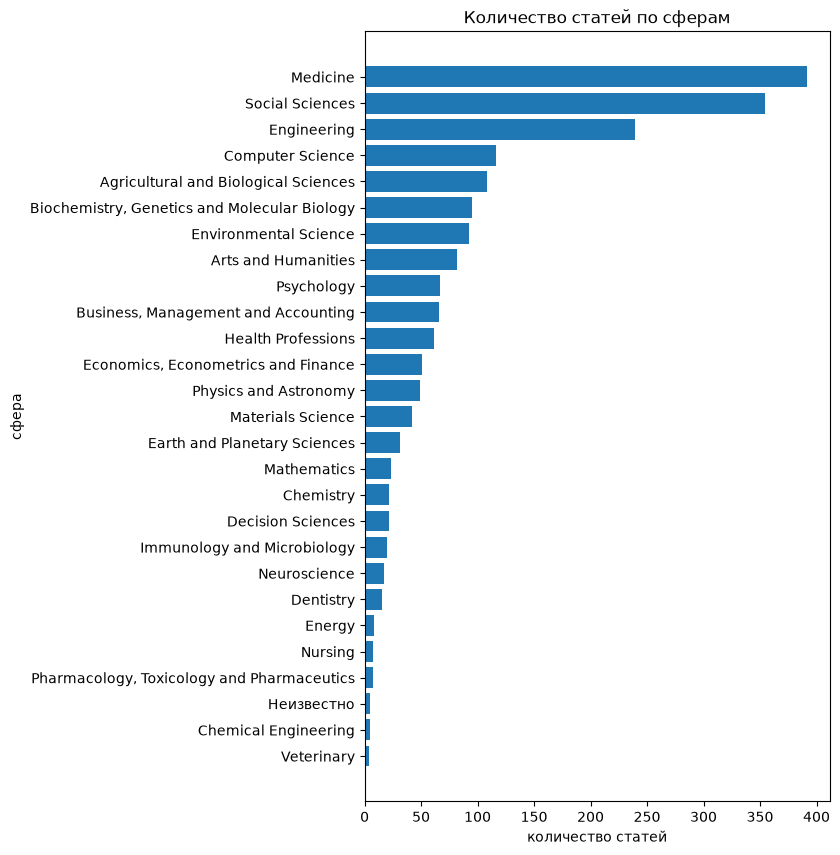

In [25]:
plt.figure(figsize=(6,10))
table=table.sort_values('count')
plt.barh(table.index, table['count'])
plt.ylabel('сфера')
plt.xlabel('количество статей')
plt.title('Количество статей по сферам')
plt.show()

На данной диаграмме видно, что больше всего статей по темам "Медицина", "Социальные науки" и "Инженерия". Меньше всего статей по темам "Ветеринарное дело", "Химическая инженерия" и "Токсикология/фармацевтика"

№9

In [26]:
new_data=copy_data.copy()
new_data['group_count']=copy_data['field'].map(table['count'])
new_data['group_mean']=new_data['field'].map(table['mean'])
new_data['delta']=new_data['citations']-new_data['group_mean']
new_data.head()

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url,group_count,group_mean,delta
0,W4386830175,Novel Terahertz-Based Radiation Treatment of A...,"Alzheimer’s Disease Facts and Figures, an annu...",NaN,Terahertz technology and applications,Engineering,2023,0,en,True,https://doi.org/10.47485/2694-5614.1020,239,9.426778,-9.426778
1,W4407611995,استخدام مفاهيم التصميم العالمى فى مدارس التعلي...,الملخص: تتناول الدراسة سبل تحقيق الاستدامة الا...,Dina Hassan Helaly Ali Ahmed,Military Technology and Strategies,Engineering,2025,0,ar,True,https://doi.org/10.21608/auber.2025.287359.1083,239,9.426778,-9.426778
2,W7154576169,A Behavioral Approach to Understanding Loss Re...,This paper takes a deep dive into historical l...,Uri Korn,Credit Risk and Financial Regulations,"Economics, Econometrics and Finance",2023,0,en,True,https://doi.org/10.66573/001c.87684,51,3.392157,-3.392157
3,W4405618890,ВЫРАЗИТЕЛЬНЫЕ ВОЗМОЖНОСТИ СОВРЕМЕННОЙ КИТАЙСКО...,В статье анализируется комплекс выразительных ...,Ю. Ли,Musicology and Musical Analysis,Arts and Humanities,2024,0,ru,True,https://doi.org/10.26176/maetam.2024.16.3.004,82,0.378049,-0.378049
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886,392,8.890306,-4.890306


In [27]:
new_data_100 = new_data.dropna(subset='citations').head(100)
new_data_100

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url,group_count,group_mean,delta
0,W4386830175,Novel Terahertz-Based Radiation Treatment of A...,"Alzheimer’s Disease Facts and Figures, an annu...",NaN,Terahertz technology and applications,Engineering,2023,0,en,True,https://doi.org/10.47485/2694-5614.1020,239,9.426778,-9.426778
1,W4407611995,استخدام مفاهيم التصميم العالمى فى مدارس التعلي...,الملخص: تتناول الدراسة سبل تحقيق الاستدامة الا...,Dina Hassan Helaly Ali Ahmed,Military Technology and Strategies,Engineering,2025,0,ar,True,https://doi.org/10.21608/auber.2025.287359.1083,239,9.426778,-9.426778
2,W7154576169,A Behavioral Approach to Understanding Loss Re...,This paper takes a deep dive into historical l...,Uri Korn,Credit Risk and Financial Regulations,"Economics, Econometrics and Finance",2023,0,en,True,https://doi.org/10.66573/001c.87684,51,3.392157,-3.392157
3,W4405618890,ВЫРАЗИТЕЛЬНЫЕ ВОЗМОЖНОСТИ СОВРЕМЕННОЙ КИТАЙСКО...,В статье анализируется комплекс выразительных ...,Ю. Ли,Musicology and Musical Analysis,Arts and Humanities,2024,0,ru,True,https://doi.org/10.26176/maetam.2024.16.3.004,82,0.378049,-0.378049
4,W4308690710,The Efficacy of an N-Acetylcysteine–Antibiotic...,Cystic fibrosis (CF) is a disorder causing dys...,Aditi Aiyer | Theerthankar Das | Greg S. White...,Cystic Fibrosis Research Advances,Medicine,2022,4,en,True,https://doi.org/10.3390/biomedicines10112886,392,8.890306,-4.890306
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,W7141106858,The algorithm of the simulation model implemen...,The article is devoted to the issues of foreca...,G. L. Ogurtsov | N. A. Ermoshin | O. R. Biryukov,Concrete Corrosion and Durability,Engineering,2025,1,NaN,True,https://doi.org/10.52170/1815-9265_2025_73_104,239,9.426778,-8.426778
96,W4281706678,3D CITY MODELS AS A 3D CADASTRAL LAYER: THE CA...,Abstract. Optimal land administration systems;...,İsmail Dursun | Mustafa Kaan Aslan | İ. Cankur...,3D Modeling in Geospatial Applications,Engineering,2022,4,en,True,https://doi.org/10.5194/isprs-archives-xliii-b...,239,9.426778,-5.426778
97,W3023679119,SAT-597 Hypothalamic ESR1 Gene Knockdown Elici...,Abstract Declining serum estradiol (E2) levels...,Molly M Willging | Jon E. Levine | Emily P. Gr...,Adipose Tissue and Metabolism,Medicine,2020,0,en,True,https://doi.org/10.1210/jendso/bvaa046.1807,392,8.890306,-8.890306
98,W4385669441,Saving and Empowering young lives in PAKistan ...,Introduction Suicide is a leading cause of dea...,Maria Panagioti | Tayyeba Kiran | Saba Irshad ...,Suicide and Self-Harm Studies,Psychology,2023,1,en,True,https://doi.org/10.1192/j.eurpsy.2023.703,67,13.149254,-12.149254


Рисуем график

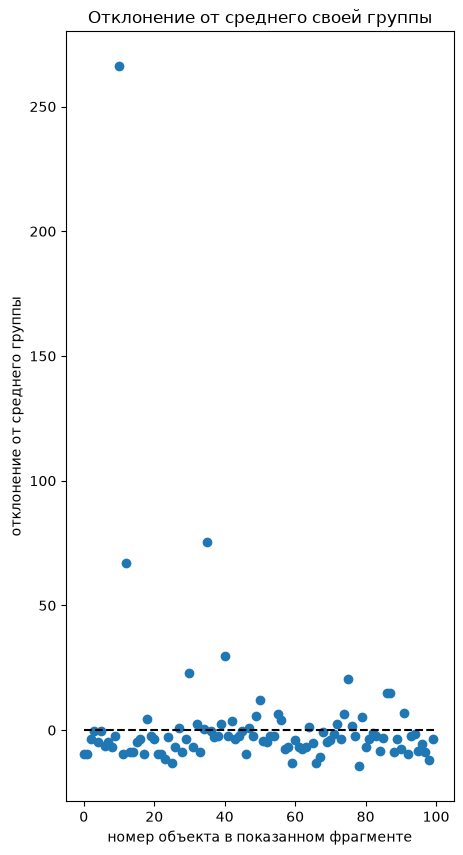

In [28]:
plt.figure(figsize=(5,10))
plt.scatter(new_data_100.index, new_data_100['delta'])
plt.plot([0,100],[0,0], color='black', linestyle='--')
plt.xlabel('номер объекта в показанном фрагменте')
plt.ylabel('отклонение от среднего группы')
plt.title('Отклонение от среднего своей группы')
plt.show()

Вывод: есть выброс в большую сторону, но большинство значений меньше среднего.

In [29]:
sort_data_100=new_data_100.sort_values('delta')
sort_data_100

,id,title,abstract,authors,topic,field,year,citations,language,open_access,url,group_count,group_mean,delta
78,W4377193519,Adsorption Properties of Boron on Hydrogels Ha...,本研究では，ホウ素をターゲットとした高容量の吸着材として，ポリエチレンイミン，水酸基を4つ有...,Daiki Matsumura | Kazunori Nakano,Mesoporous Materials and Catalysis,Materials Science,2023,0,en,True,https://doi.org/10.1252/kakoronbunshu.49.62,42,14.523810,-14.523810
25,W7105797697,Death Rituals of the Halam Community: A Compre...,The Halam community of Tripura represents a un...,"Halam, Jekap","Grief, Bereavement, and Mental Health",Psychology,2025,0,NaN,True,https://doi.org/10.5281/zenodo.17614447,67,13.149254,-13.149254
66,W4387831216,MOTIVAÇÃO E AUTOCONCEITO DE ALUNOS COM SOBREPE...,RESUMO A presente pesquisa tem como objetivo g...,Flávia Gabriela Meserlian | Katya Luciane de O...,Motivation and Self-Concept in Sports,Psychology,2023,0,pt,True,https://doi.org/10.1590/2175-35392023-242122,67,13.149254,-13.149254
59,W3200794481,Du oder Sie?,Chapter Preview,Barbara Willms,"Psychology, Coaching, and Therapy",Psychology,2021,0,de,True,https://doi.org/10.51202/0042-1758-2021-36-31,67,13.149254,-13.149254
98,W4385669441,Saving and Empowering young lives in PAKistan ...,Introduction Suicide is a leading cause of dea...,Maria Panagioti | Tayyeba Kiran | Saba Irshad ...,Suicide and Self-Harm Studies,Psychology,2023,1,en,True,https://doi.org/10.1192/j.eurpsy.2023.703,67,13.149254,-12.149254
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30,W4386211792,A possible mechanism for the enhanced toxicity...,The amyloid-beta peptide (Aβ) is a driver of A...,Zu‐Lin Chen | Pradeep Kumar Singh | Marissa Ca...,Alzheimer's disease research and treatments,Medicine,2023,32,en,True,https://doi.org/10.1073/pnas.2309389120,392,8.890306,23.109694
40,W4390744711,Understanding Phakopsora pachyrhizi in soybean...,Soybean (Glycine max L.) is an important crop ...,Md. Motaher Hossain | Farjana Sultana | Laboni...,Yeasts and Rust Fungi Studies,"Biochemistry, Genetics and Molecular Biology",2024,41,en,True,https://doi.org/10.3389/fmicb.2023.1304205,95,11.452632,29.547368
12,W4386379189,Overcoming Mycobacterium tuberculosis Drug Res...,High Resolution Image Download MS PowerPoint S...,Rohan Samir Kumar Sachan | Vyoma Mistry | Mayu...,Tuberculosis Research and Epidemiology,Medicine,2023,76,en,True,https://doi.org/10.1021/acsomega.3c02563,392,8.890306,67.109694
35,W4380989507,Effect of scanning speed and laser power on fo...,Selective Laser Melting (SLM) prepared 316L st...,Liang Hao | Wanlin Wang | Jie Zeng | Min Jung ...,Additive Manufacturing Materials and Processes,Engineering,2023,85,en,True,https://doi.org/10.1016/j.jmrt.2023.06.144,239,9.426778,75.573222


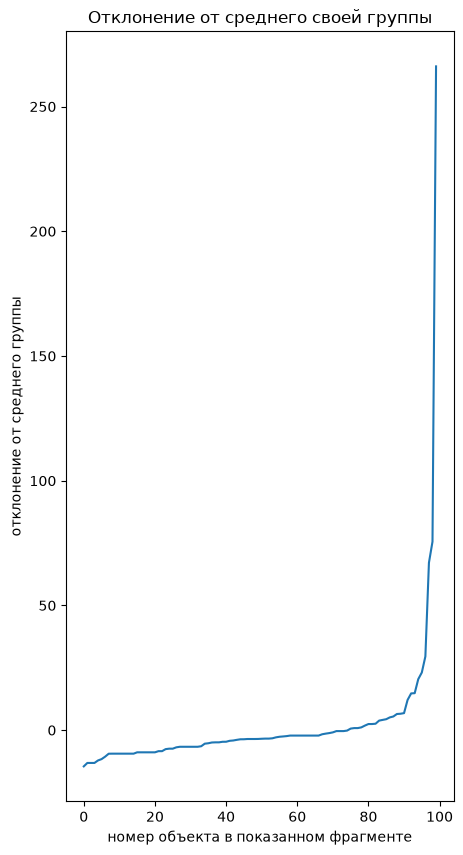

In [30]:
plt.figure(figsize=(5,10))
plt.plot(range(len(sort_data_100['delta'])), sort_data_100['delta'])
plt.xlabel('номер объекта в показанном фрагменте')
plt.ylabel('отклонение от среднего группы')
plt.title('Отклонение от среднего своей группы')
plt.show()

№10

In [32]:
copy_data['citations'].quantile([0.25, 0.5, 0.75])


0.25    0.0
0.50    1.0
0.75    6.0
Name: citations, dtype: float64

In [35]:
max_5_table = table.nlargest(5,'count')
max_5_table

,count,mean,median,proportion,NaN
field,,,,,
Medicine,392,8.890306,2.0,0.017818,0
Social Sciences,354,2.177966,0.0,0.016091,0
Engineering,239,9.426778,1.0,0.010864,0
Computer Science,116,3.551724,0.0,0.005273,0
Agricultural and Biological Sciences,108,6.666667,2.0,0.004909,0


In [40]:
data_quant = copy_data[copy_data['field'].isin(max_5_table.index)]
data_quant.groupby('field')['citations'].quantile([0.25,0.5,0.75])

field                                     
Agricultural and Biological Sciences  0.25     0.00
                                      0.50     2.00
                                      0.75     7.00
Computer Science                      0.25     0.00
                                      0.50     0.00
                                      0.75     3.25
Engineering                           0.25     0.00
                                      0.50     1.00
                                      0.75     9.00
Medicine                              0.25     0.00
                                      0.50     2.00
                                      0.75    10.00
Social Sciences                       0.25     0.00
                                      0.50     0.00
                                      0.75     2.00
Name: citations, dtype: float64

Полный график:

(array([1, 2, 3, 4, 5]),
 [Text(1, 0, 'Agricultural and Biological Sciences'),
  Text(2, 0, 'Computer Science'),
  Text(3, 0, 'Engineering'),
  Text(4, 0, 'Medicine'),
  Text(5, 0, 'Social Sciences')])

<Figure size 500x1000 with 0 Axes>

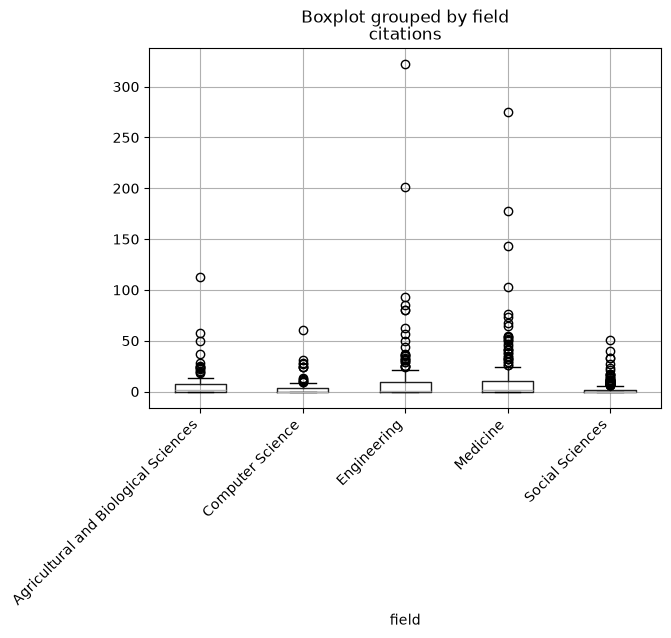

In [61]:
plt.figure(figsize=(5,10))
data_quant.boxplot(column='citations', by='field')
plt.xticks(rotation=45, ha='right')

Более наглядный (обрезанный) график:

(0.0, 30.0)

<Figure size 500x1000 with 0 Axes>

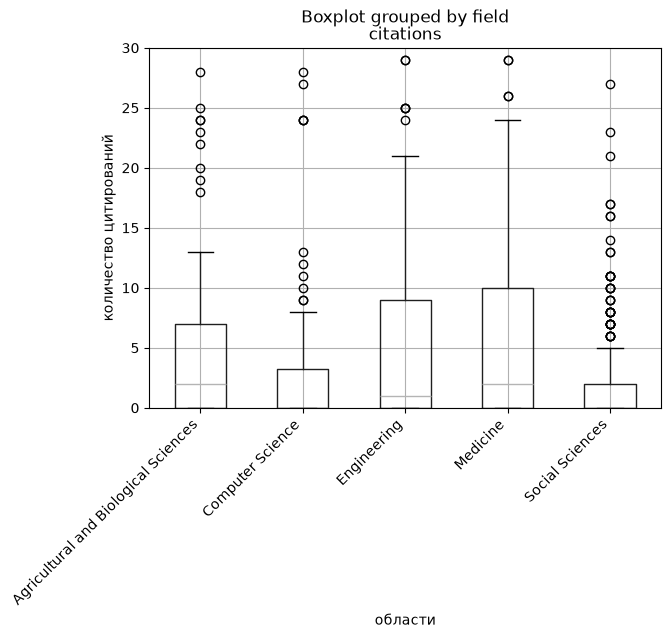

In [63]:
plt.figure(figsize=(5,10))
data_quant.boxplot(column='citations', by='field')
plt.xticks(rotation=45, ha='right')
plt.xlabel('области')
plt.ylabel('количество цитирований')
plt.ylim(0,30)

По графику видно, что самые высокие медианы у областей "Медицина" и "Биологические науки". При этом у целых двух областей квантили 0.25 и 0.5 совпадают и равняются нулю. Квантиль 0.25 равен нулю у каждой из областей. Это значит, что цитирование статей в этих областях не очень частое, многие статьи не цитируются вообще. При этом существуют выбросы, самый большой разброс наблюдается в областях "Инженерия" и "Медицина" (наибольшая разница между квантилем 0.5 и 0.75). Самая заметная аномалия - выброс статьи из области "Инженерия", ее значение превышает 300.